# 04 - Entalpía de Formación a partir de los Polinomios de la NASA

La **entalpía de formación estándar** $\Delta_f H^\circ$ es el cambio de entalpía
cuando un mol de una especie se forma a partir de sus elementos en sus estados de
referencia a 298,15 K y 1 bar. Por definición es **cero** para un elemento en su
estado de referencia (O₂, N₂, H₂, grafito, ...).

`pyglenn` ofrece dos rutas equivalentes hacia $\Delta_f H^\circ$:

1. `calculate_formation_enthalpy(id)` — lee la columna dedicada
   `heat_of_formation_298K` (poblada desde pyglenn 0.2.0);
2. `calculate_properties(id, 298.15).h_relative` — la entalpía estandarizada,
   que equivale a $\Delta_f H^\circ$ a 298,15 K porque los polinomios de la NASA
   ajustan la escala *estandarizada*.

Este cuaderno valida ambas rutas contra la literatura y muestra que coinciden.


In [1]:
from pyglenn import ThermochemicalCalculator, R

print("Universal gas constant R =", R, "J/(mol.K)")


Universal gas constant R = 8.31446261815324 J/(mol.K)


In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


## 1. El método dedicado (poblado desde 0.2.0)

La columna `heat_of_formation_298K` ahora está poblada en la base de datos
empaquetada, así que `calculate_formation_enthalpy` devuelve el valor tabulado
directamente en J/mol. (Antes de 0.2.0 esta columna estaba vacía y el método
devolvía `None`.)


In [3]:
with ThermochemicalCalculator() as calc:
    for name in ["H2O", "CO2", "CH4", "O2", "N2"]:
        sid = calc.get_available_species(name, exact_match=True)[0].id
        dhf = calc.calculate_formation_enthalpy(sid)
        print(f"{name:5s} calculate_formation_enthalpy -> {dhf/1000:9.2f} kJ/mol")


H2O   calculate_formation_enthalpy ->   -241.83 kJ/mol
CO2   calculate_formation_enthalpy ->   -393.51 kJ/mol
CH4   calculate_formation_enthalpy ->    -74.60 kJ/mol
O2    calculate_formation_enthalpy ->      0.00 kJ/mol
N2    calculate_formation_enthalpy ->      0.00 kJ/mol


## 2. El mismo valor desde el polinomio

La entalpía estandarizada ya contiene la entalpía de formación, por lo que a
298,15 K *es* $\Delta_f H^\circ$ — la misma cantidad que devuelve el método
dedicado. Los elementos en estado de referencia resultan esencialmente cero
(salvo redondeo del ajuste).


In [4]:
def formation_enthalpy(calc, name, T=298.15):
    """Delta_f H a T (por defecto 298,15 K), en J/mol, desde la H estandarizada."""
    return calc.calculate_properties(calc.get_available_species(name, exact_match=True)[0].id, T).h_relative

with ThermochemicalCalculator() as calc:
    print("Elementos en estado de referencia (deben ser ~0):")
    for el in ["O2", "N2", "H2", "C(gr)"]:
        print(f"  {el:6s} {formation_enthalpy(calc, el)/1000: .4f} kJ/mol")

    print("\nMétodo dedicado vs recuperación polinómica:")
    for name in ["H2O", "CO2", "CH4", "NH3", "NO"]:
        sid = calc.get_available_species(name, exact_match=True)[0].id
        dedicated = calc.calculate_formation_enthalpy(sid) / 1000.0
        poly = formation_enthalpy(calc, name) / 1000.0
        print(f"  {name:5s} dedicado={dedicated:9.2f}  polinomio={poly:9.2f}  diff={abs(dedicated-poly):.2e} kJ/mol")


Elementos en estado de referencia (deben ser ~0):
  O2     -0.0000 kJ/mol
  N2      0.0000 kJ/mol
  H2     -0.0000 kJ/mol
  C(gr)   0.0000 kJ/mol

Método dedicado vs recuperación polinómica:
  H2O   dedicado=  -241.83  polinomio=  -241.83  diff=3.40e-07 kJ/mol
  CO2   dedicado=  -393.51  polinomio=  -393.51  diff=3.21e-08 kJ/mol
  CH4   dedicado=   -74.60  polinomio=   -74.60  diff=1.39e-08 kJ/mol
  NH3   dedicado=   -45.94  polinomio=   -45.94  diff=2.52e-08 kJ/mol
  NO    dedicado=    91.27  polinomio=    91.27  diff=1.24e-08 kJ/mol


## 3. Una tabla validada de entalpías de formación

Calculamos $\Delta_f H^\circ$ para un conjunto de especies comunes y comparamos
con valores aceptados de la literatura (CODATA / JANAF, fase gaseosa). La
concordancia está dentro de 1 kJ/mol — los polinomios reproducen los datos de
referencia a los que fueron ajustados.

In [5]:
# Entalpías estándar de formación de la literatura a 298,15 K, kJ/mol (fase gaseosa)
REFERENCE = {
    "H2": 0.0, "O2": 0.0, "N2": 0.0, "C(gr)": 0.0,
    "H2O": -241.83, "CO2": -393.52, "CO": -110.53, "CH4": -74.87,
    "NH3": -45.90, "NO": 91.29, "NO2": 33.10, "C2H5OH": -235.0,
}

records = []
with ThermochemicalCalculator() as calc:
    for name, ref in REFERENCE.items():
        sid = calc.get_available_species(name, exact_match=True)[0].id
        M = calc.db.get_species_data(sid).molecular_weight
        dhf = formation_enthalpy(calc, name) / 1000.0
        records.append({
            "especie": name, "M [g/mol]": M,
            "pyglenn [kJ/mol]": dhf, "referencia [kJ/mol]": ref,
            "error abs. [kJ/mol]": abs(dhf - ref),
        })

hf_df = pd.DataFrame(records).set_index("especie")
print(hf_df.to_string())
print(f"\nMayor error absoluto: {hf_df['error abs. [kJ/mol]'].max():.3f} kJ/mol")

         M [g/mol]  pyglenn [kJ/mol]  referencia [kJ/mol]  error abs. [kJ/mol]
especie                                                                       
H2           2.016            -0.000                0.000                0.000
O2          31.999            -0.000                0.000                0.000
N2          28.013             0.000                0.000                0.000
C(gr)       12.011             0.000                0.000                0.000
H2O         18.015          -241.826             -241.830                0.004
CO2         44.010          -393.510             -393.520                0.010
CO          28.010          -110.535             -110.530                0.005
CH4         16.042           -74.600              -74.870                0.270
NH3         17.031           -45.940              -45.900                0.040
NO          30.006            91.271               91.290                0.019
NO2         46.005            34.193               3

## 4. Visualizando entalpías de formación

Un gráfico de barras horizontales hace evidente la división entre especies
exotérmicas ($\Delta_f H^\circ$ negativo, estables) y endotérmicas (positivo,
energéticas). Los elementos se sitúan exactamente sobre la línea del cero.

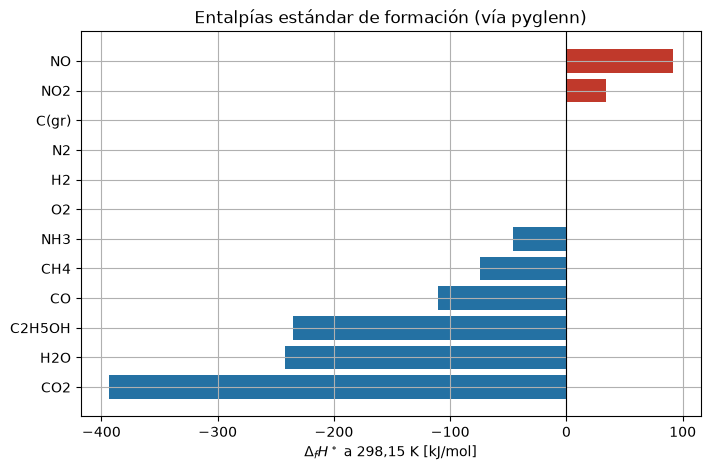

In [6]:
order = hf_df.sort_values("pyglenn [kJ/mol]")
vals = order["pyglenn [kJ/mol]"]
colors = ["#c0392b" if v > 0 else ("#7f8c8d" if abs(v) < 1e-3 else "#2471a3")
          for v in vals]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(order.index, vals, color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel(r"$\Delta_f H^\circ$ a 298,15 K [kJ/mol]")
ax.set_title("Entalpías estándar de formación (vía pyglenn)")
plt.show()

## 5. Solo 298,15 K es "formación"

$\Delta_f H^\circ$ se define a 298,15 K. La entalpía estandarizada $H^\circ(T)$
sigue variando con la temperatura, pero solo su valor a 298,15 K iguala la
entalpía de formación tabulada. Para el CO₂, trazamos $H^\circ(T)$ y destacamos
ese punto de referencia; el desplazamiento vertical por encima es la entalpía
*sensible* $H^\circ(T)-H^\circ(298{,}15)$ del cuaderno 03.

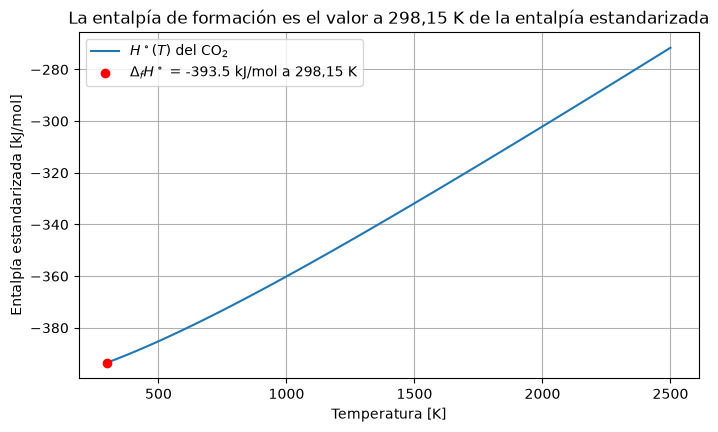

In [7]:
Tgrid = np.linspace(300, 2500, 60)
with ThermochemicalCalculator() as calc:
    co2 = calc.get_available_species("CO2", exact_match=True)[0].id
    H = np.array([calc.calculate_properties(co2, t).h_relative for t in Tgrid]) / 1000.0
    hf298 = formation_enthalpy(calc, "CO2") / 1000.0

fig, ax = plt.subplots()
ax.plot(Tgrid, H, label=r"$H^\circ(T)$ del CO$_2$")
ax.scatter([298.15], [hf298], color="red", zorder=5,
           label=fr"$\Delta_f H^\circ$ = {hf298:.1f} kJ/mol a 298,15 K")
ax.set_xlabel("Temperatura [K]")
ax.set_ylabel("Entalpía estandarizada [kJ/mol]")
ax.set_title("La entalpía de formación es el valor a 298,15 K de la entalpía estandarizada")
ax.legend()
plt.show()

## Resumen

- `calculate_formation_enthalpy` ahora devuelve el $\Delta_f H^\circ$ tabulado
  (la columna `heat_of_formation_298K` está poblada desde 0.2.0).
- `calculate_properties(id, 298.15).h_relative` da el mismo valor — la entalpía
  estandarizada de la NASA lleva la entalpía de formación.
- Ambas rutas reproducen los valores de la literatura con < 1 kJ/mol.

**Siguiente:** el cuaderno 05 usa exactamente esto para calcular entalpías de
reacción y calores de combustión.
